In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [27]:
df = pd.read_csv("credit_card_debt.csv")
df.shape

(35912, 15)

In [28]:
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

## 1. Column types
Check that each column has a sensible type. Dates stored as text cannot be sorted or subtracted,
so convert them first (this changes the type only, not the values or the row count).

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35912 entries, 0 to 35911
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   Date received                 35912 non-null  str  
 1   Product                       35912 non-null  str  
 2   Sub-product                   35912 non-null  str  
 3   Issue                         35912 non-null  str  
 4   Sub-issue                     35912 non-null  str  
 5   Company public response       7614 non-null   str  
 6   Company                       35912 non-null  str  
 7   State                         35838 non-null  str  
 8   ZIP code                      35604 non-null  str  
 9   Tags                          4128 non-null   str  
 10  Submitted via                 35912 non-null  str  
 11  Date sent to company          35912 non-null  str  
 12  Company response to consumer  35912 non-null  str  
 13  Timely response?              35912 non-nu

In [5]:
df["Date received"] = pd.to_datetime(df["Date received"])
df["Date sent to company"] = pd.to_datetime(df["Date sent to company"])
df.dtypes

Date received                   datetime64[us, UTC]
Product                                         str
Sub-product                                     str
Issue                                           str
Sub-issue                                       str
Company public response                         str
Company                                         str
State                                           str
ZIP code                                        str
Tags                                            str
Submitted via                                   str
Date sent to company            datetime64[us, UTC]
Company response to consumer                    str
Timely response?                                str
Complaint ID                                  int64
dtype: object

In [6]:
# Unique values per column: low counts = categorical, one value = constant, ~n_rows = identifier
pd.DataFrame({"unique": df.nunique(), "example": df.iloc[0]})

,unique,example
Date received,35866,2026-07-31 13:52:56+00:00
Product,1,Debt collection
Sub-product,1,Credit card debt
Issue,7,Took or threatened to take negative or legal action
Sub-issue,29,Seized or attempted to seize your property
Company public response,9,NaN
Company,843,Triton Recovery Group
State,56,MD
ZIP code,7648,21216
Tags,3,NaN


## 2. Missing values
Count blanks per column, then ask *why* each is blank before deciding what to do.

In [32]:
missing = pd.DataFrame({"n_missing": df.isna().sum(), "pct_missing": (df.isna().mean() * 100).round(1)})
missing[missing.n_missing > 0].sort_values("n_missing", ascending=False)

,n_missing,pct_missing
Tags,31784,88.5
Company public response,28298,78.8
ZIP code,308,0.9
State,74,0.2


In [8]:
# Are blanks tied to a group? Share of blank Company public response by response outcome
(df.assign(public_blank=df["Company public response"].isna())
   .groupby("Company response to consumer")["public_blank"].agg(["sum", "size", "mean"]).round(3))

,sum,size,mean
Company response to consumer,,,
Closed with explanation,19309,25219,0.766
Closed with monetary relief,78,142,0.549
Closed with non-monetary relief,7639,9279,0.823
In progress,997,997,1.000
Untimely response,275,275,1.000


## 3. Duplicate records

In [ ]:
print("Repeated Complaint IDs:", df["Complaint ID"].duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())
# Same content under different IDs (could be the same person filing twice, or legitimate repeats)
cols_no_id = [c for c in df.columns if c != "Complaint ID"]
print("Rows identical except for Complaint ID:", df.duplicated(subset=cols_no_id, keep=False).sum())
print("Repeated Issue:", df["Issue"].value_counts())


Repeated Complaint IDs: 0
Fully duplicated rows: 0
Rows identical except for Complaint ID: 0
Repeated Issue: Issue
Attempts to collect debt not owed                                17028
Written notification about debt                                   6383
False statements or representation                                4390
Took or threatened to take negative or legal action               3751
Communication tactics                                             2393
Electronic communications                                         1256
Threatened to contact someone or share information improperly      711
Name: count, dtype: int64


In [10]:
# Look at them before deciding anything
df[df.duplicated(subset=cols_no_id, keep=False)].sort_values(cols_no_id).head(10)

,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID


## 4. Impossible or suspicious entries
Look for values that cannot be true (dates in the wrong order, dates in the future) and for
values that are possible but odd.

In [11]:
df["Days to company"] = (df["Date sent to company"] - df["Date received"]).dt.days
print("Date range received:", df["Date received"].min().date(), "to", df["Date received"].max().date())
print("Sent to company before received:", (df["Days to company"] < 0).sum())
today = pd.Timestamp.now(tz=df["Date received"].dt.tz)   # matches the column's time zone setting
print("Received after today:", (df["Date received"] > today).sum())
print("Non-positive or non-integer Complaint IDs:", ((df["Complaint ID"] <= 0) | (df["Complaint ID"] % 1 != 0)).sum())

Date range received: 2025-10-27 to 2026-10-26
Sent to company before received: 0
Received after today: 0
Non-positive or non-integer Complaint IDs: 0


In [12]:
# ZIP codes are masked by CFPB (e.g. 301XX). Check the pattern, and that State has valid codes.
zip_ok = df["ZIP code"].dropna().astype(str).str.fullmatch(r"\d{3}XX|\d{5}")
print("ZIP codes not matching 5 digits or 3 digits + XX:", (~zip_ok).sum())
print(df.loc[zip_ok[~zip_ok].index, "ZIP code"].value_counts().head())

states_50_dc = set("AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC".split())
other = df.loc[~df["State"].isin(states_50_dc) & df["State"].notna(), "State"].value_counts()
print("\nState values other than the 50 states and DC (territories, military, etc.):")
print(other)

ZIP codes not matching 5 digits or 3 digits + XX: 288
ZIP code
XXXXX    288
Name: count, dtype: int64

State values other than the 50 states and DC (territories, military, etc.):
State
PR                                      91
AP                                       8
VI                                       7
UNITED STATES MINOR OUTLYING ISLANDS     6
AE                                       3
Name: count, dtype: int64


In [13]:
# Constant columns carry no information for comparisons
for col in ["Product", "Sub-product"]:
    print(col, "->", df[col].unique())

Product -> <StringArray>
['Debt collection']
Length: 1, dtype: str
Sub-product -> <StringArray>
['Credit card debt']
Length: 1, dtype: str


## 5. Inconsistent categories
The same label written two ways (case, spacing, punctuation) splits one category into two.

In [14]:
cat_cols = ["Issue", "Sub-issue", "Company response to consumer", "Company public response",
            "Submitted via", "Timely response?", "Tags"]
for col in cat_cols:
    s = df[col].dropna().astype(str)
    key = s.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
    variants = s.groupby(key).nunique()
    pad = (s != s.str.strip()).sum()
    print(f"{col:32s} categories={s.nunique():3d}  label variants={int((variants > 1).sum())}  leading/trailing spaces={pad}")

Issue                            categories=  7  label variants=0  leading/trailing spaces=0
Sub-issue                        categories= 29  label variants=0  leading/trailing spaces=0
Company response to consumer     categories=  5  label variants=0  leading/trailing spaces=0
Company public response          categories=  9  label variants=0  leading/trailing spaces=0
Submitted via                    categories=  4  label variants=0  leading/trailing spaces=0
Timely response?                 categories=  2  label variants=0  leading/trailing spaces=0
Tags                             categories=  3  label variants=0  leading/trailing spaces=0


In [15]:
# Company names: the same company can appear under spelling variants
co = df["Company"].dropna().astype(str)
co_key = co.str.lower().str.replace(r"\b(inc|llc|l\.?p|corp|corporation|co|company|ltd)\b", "", regex=True).str.replace(r"[^a-z0-9]", "", regex=True)
multi = co.groupby(co_key).nunique()
multi = multi[multi > 1]
print("Company names that collapse together after normalizing:", len(multi))
for k in multi.index[:10]:
    print(" ", sorted(co[co_key == k].unique()))

Company names that collapse together after normalizing: 2
  ['Ragan & Ragan, P.C.', 'Ragan & Ragan, PC']
  ['USCB Corporation', 'USCB, Inc.']


In [16]:
df["Issue"].value_counts()

Issue
Attempts to collect debt not owed                                17028
Written notification about debt                                   6383
False statements or representation                                4390
Took or threatened to take negative or legal action               3751
Communication tactics                                             2393
Electronic communications                                         1256
Threatened to contact someone or share information improperly      711
Name: count, dtype: int64

## 6. Extreme observations
Almost every column is categorical, so the main numeric variable is `Days to company`.
Most values are 0, so the usual IQR rule would flag every nonzero value. Use a percentile instead.

In [17]:
d = df["Days to company"]
print(d.describe())
print("Sent the same day:", f"{(d == 0).mean():.1%}")
p99 = d.quantile(0.99)
extreme = df[d > p99]
print(f"\n99th percentile = {p99:.0f} days; {len(extreme):,} rows ({len(extreme)/len(df):.1%}) are above it")

count    35912.000000
mean         2.278876
std         10.495947
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        193.000000
Name: Days to company, dtype: float64
Sent the same day: 92.4%

99th percentile = 52 days; 319 rows (0.9%) are above it


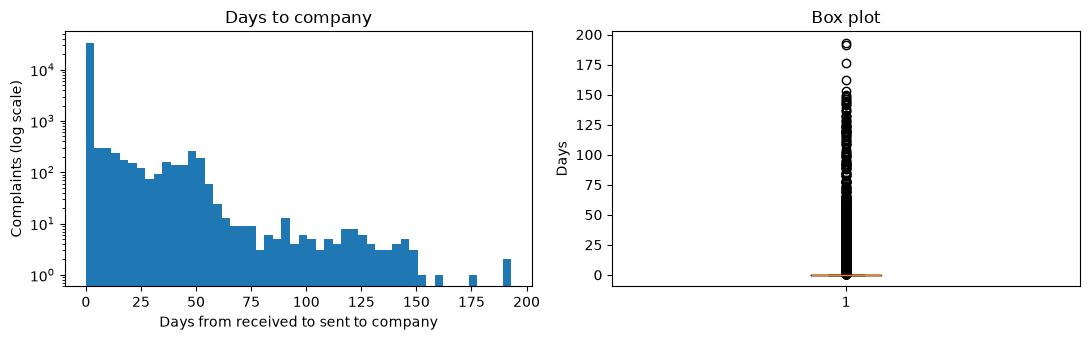

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(d, bins=50)
axes[0].set_yscale("log")
axes[0].set_xlabel("Days from received to sent to company")
axes[0].set_ylabel("Complaints (log scale)")
axes[0].set_title("Days to company")
axes[1].boxplot(d)
axes[1].set_ylabel("Days")
axes[1].set_title("Box plot")
plt.tight_layout()
plt.show()

In [19]:
# Do the extreme delays cluster around a few companies or one response type?
print(extreme["Company"].value_counts().head(5))
print()
print(extreme["Company response to consumer"].value_counts())

Company
ENCORE CAPITAL GROUP INC.             22
Resurgent Capital Services L.P.       22
Portfolio Recovery Associates, LLC    21
Bread Financial Holdings, Inc.        17
Credit Corp Solutions Inc.            14
Name: count, dtype: int64

Company response to consumer
Closed with explanation            241
Closed with non-monetary relief     46
In progress                         21
Untimely response                    7
Closed with monetary relief          4
Name: count, dtype: int64


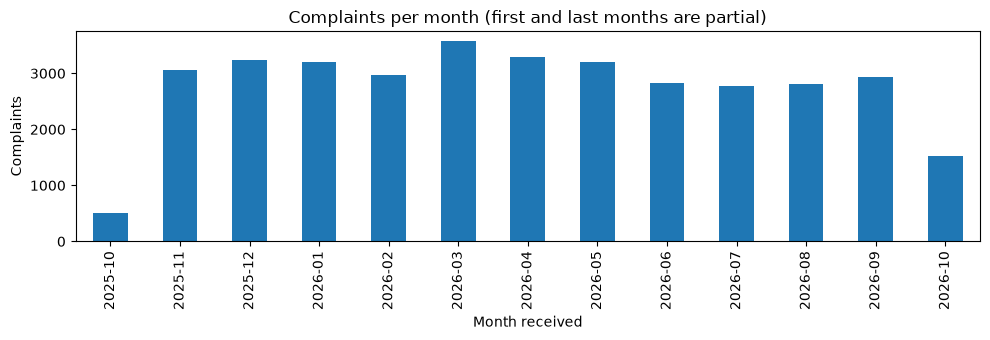

In [20]:
# Volume over time: partial first and last months look like dips but are not real drops
monthly = df.groupby(df["Date received"].dt.strftime("%Y-%m")).size()
ax = monthly.plot(kind="bar", figsize=(10, 3.5))
ax.set_xlabel("Month received")
ax.set_ylabel("Complaints")
ax.set_title("Complaints per month (first and last months are partial)")
plt.tight_layout()
plt.show()

## 7. Underrepresented groups and outcomes
Flag any category with fewer than 1% of rows or fewer than 100 complaints. Report these with their
counts, and avoid strong conclusions from them.

In [21]:
def rep_table(col):
    n = df[col].value_counts()
    t = pd.DataFrame({"n": n, "pct": (n / len(df) * 100).round(2)})
    t["underrepresented"] = (t["pct"] < 1) | (t["n"] < 100)
    return t

for col in ["Company response to consumer", "Submitted via", "Timely response?"]:
    print(rep_table(col), "\n")

                                     n    pct  underrepresented
Company response to consumer                                   
Closed with explanation          25219  70.22             False
Closed with non-monetary relief   9279  25.84             False
In progress                        997   2.78             False
Untimely response                  275   0.77              True
Closed with monetary relief        142   0.40              True 

                   n    pct  underrepresented
Submitted via                                
Web            35343  98.42             False
Phone            255   0.71              True
Referral         181   0.50              True
Postal mail      133   0.37              True 

                      n    pct  underrepresented
Timely response?                                
Yes               35414  98.61             False
No                  498   1.39             False 



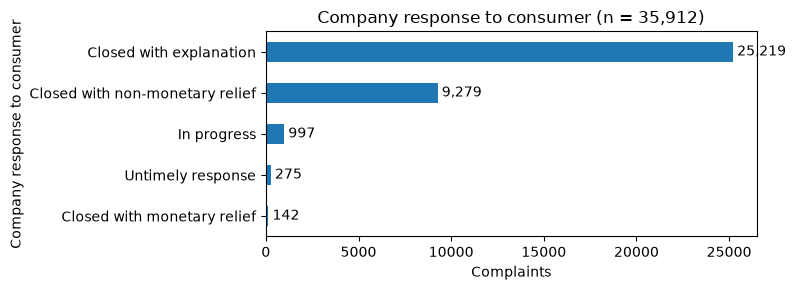

In [22]:
ax = df["Company response to consumer"].value_counts().sort_values().plot(kind="barh", figsize=(8, 3))
ax.set_xlabel("Complaints")
ax.set_title("Company response to consumer (n = %s)" % f"{len(df):,}")
for i, v in enumerate(df["Company response to consumer"].value_counts().sort_values()):
    ax.text(v, i, f" {v:,}", va="center")
plt.tight_layout()
plt.show()

In [23]:
# Issues, states and companies below the threshold
for col in ["Issue", "State"]:
    t = rep_table(col)
    print(f"{col}: {int(t.underrepresented.sum())} of {len(t)} categories under 1% or 100 rows")
    print(t[t.underrepresented].head(8), "\n")

co = df["Company"].value_counts()
print("Companies:", len(co), "| with fewer than 10 complaints:", int((co < 10).sum()))
print(f"Top 3 companies = {co.head(3).sum() / len(df):.1%} of complaints")
co.head(3)

Issue: 0 of 7 categories under 1% or 100 rows
Empty DataFrame
Columns: [n, pct, underrepresented]
Index: [] 

State: 31 of 56 categories under 1% or 100 rows
         n   pct  underrepresented
State                             
MO     351  0.98              True
MS     347  0.97              True
KY     277  0.77              True
AR     261  0.73              True
WI     258  0.72              True
OK     200  0.56              True
UT     199  0.55              True
OR     196  0.55              True 

Companies: 843 | with fewer than 10 complaints: 635
Top 3 companies = 38.6% of complaints


Company
Resurgent Capital Services L.P.       5907
ENCORE CAPITAL GROUP INC.             4497
Portfolio Recovery Associates, LLC    3450
Name: count, dtype: int64

In [24]:
# Underrepresented outcomes within each issue: small cells make row proportions unreliable
ct = pd.crosstab(df["Issue"], df["Company response to consumer"])
ct["total"] = ct.sum(axis=1)
ct

Company response to consumer,Closed with explanation,Closed with monetary relief,Closed with non-monetary relief,In progress,Untimely response,total
Issue,,,,,,
Attempts to collect debt not owed,11789,82,4474,556,127,17028
Communication tactics,1305,8,983,55,42,2393
Electronic communications,822,3,402,18,11,1256
False statements or representation,3367,21,864,113,25,4390
Threatened to contact someone or share information improperly,479,0,209,17,6,711
Took or threatened to take negative or legal action,2797,15,830,71,38,3751
Written notification about debt,4660,13,1517,167,26,6383


## 8. Observation log
Write one line per finding: what you saw, and what you did about it. Do not remove unusual rows
just because they are unusual.

| Area | Observation | Handling |
|---|---|---|
| Column types | | |
| Missing values | | |
| Duplicates | | |
| Impossible / suspicious | | |
| Inconsistent categories | | |
| Extreme observations | | |
| Underrepresented groups | | |